# Verification of Figure 7.2 (Sutton & Barto, Example 7.1)
## n-step TD prediction on the 19-state random walk (on-line vs off-line updating)

### Setup
* Non-terminal states 1..19, terminal states 0 (left, reward -1) and 20 (right, reward +1)
* Start in the centre state (10); move left/right with probability 0.5 each
* $\gamma = 1$, $V(s)$ initialised to 0
* True values: $v(s) = (s - 10) / 10$
* Error measure: RMS error over the 19 states at the END of each episode, averaged over the first 10 episodes and 100 independent runs (the same 100 sets of walks are used for every method).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
# Environment and Experiment Parameters
N_STATES = 19
TERM_L, TERM_R = 0, N_STATES + 1
START = (N_STATES + 1) // 2
TRUE_V = (np.arange(1, N_STATES + 1) - START) / START   # v(s) = (s-10)/10
N_EPISODES = 10
N_RUNS = 100
GAMMA = 1.0

In [3]:
print("=" * 55)
print("RANDOM WALK ENVIRONMENT CONFIGURATION")
print("=" * 55)

print(f"Number of non-terminal states : {N_STATES}")
print(f"Left terminal state           : {TERM_L}")
print(f"Right terminal state          : {TERM_R}")
print(f"Starting state                : {START}")
print(f"Discount factor (gamma)       : {GAMMA}")
print(f"Number of independent runs    : {N_RUNS}")
print(f"Episodes per run              : {N_EPISODES}")
print(f"Total episodes                : {N_RUNS * N_EPISODES}")

print("\nTRUE STATE VALUES")
for s, value in enumerate(TRUE_V, start=1):
    print(f"State {s:2d} -> True value = {value:+.2f}")

RANDOM WALK ENVIRONMENT CONFIGURATION
Number of non-terminal states : 19
Left terminal state           : 0
Right terminal state          : 20
Starting state                : 10
Discount factor (gamma)       : 1.0
Number of independent runs    : 100
Episodes per run              : 10
Total episodes                : 1000

TRUE STATE VALUES
State  1 -> True value = -0.90
State  2 -> True value = -0.80
State  3 -> True value = -0.70
State  4 -> True value = -0.60
State  5 -> True value = -0.50
State  6 -> True value = -0.40
State  7 -> True value = -0.30
State  8 -> True value = -0.20
State  9 -> True value = -0.10
State 10 -> True value = +0.00
State 11 -> True value = +0.10
State 12 -> True value = +0.20
State 13 -> True value = +0.30
State 14 -> True value = +0.40
State 15 -> True value = +0.50
State 16 -> True value = +0.60
State 17 -> True value = +0.70
State 18 -> True value = +0.80
State 19 -> True value = +0.90


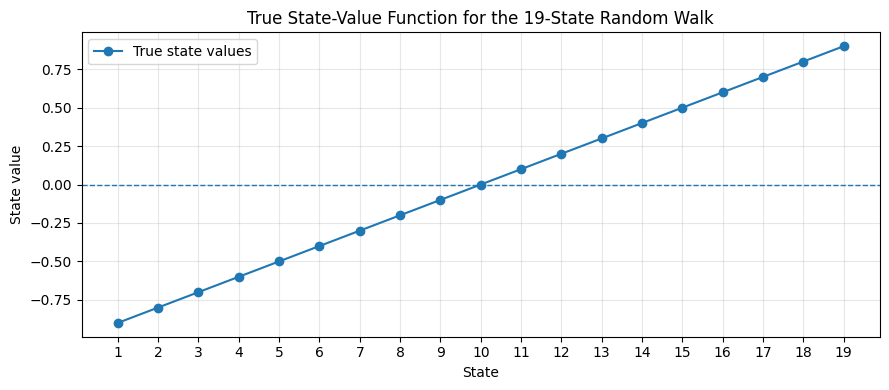

In [4]:
plt.figure(figsize=(9, 4))

plt.plot(
    range(1, N_STATES + 1),
    TRUE_V,
    marker="o",
    label="True state values"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("State")
plt.ylabel("State value")
plt.title("True State-Value Function for the 19-State Random Walk")
plt.xticks(range(1, N_STATES + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
def generate_walks(seed=0):
    """Pre-generate walks so every method sees identical experience.
    Each walk = (list of states S_0..S_T, terminal reward R_T)."""
    rng = np.random.default_rng(seed)
    runs = []
    for _ in range(N_RUNS):
        eps = []
        for _ in range(N_EPISODES):
            s, states = START, [START]
            while s not in (TERM_L, TERM_R):
                s += 1 if rng.random() < 0.5 else -1
                states.append(s)
            eps.append((states, 1.0 if s == TERM_R else -1.0))
        runs.append(eps)
    return runs

In [6]:
# Generate random walks for all runs and episodes
runs = generate_walks(seed=0)

print("Random walks generated successfully!")
print(f"Number of independent runs: {len(runs)}")
print(f"Episodes per run: {len(runs[0])}")

Random walks generated successfully!
Number of independent runs: 100
Episodes per run: 10


In [7]:
sample_states, sample_reward = runs[0][0]

print("=" * 55)
print("SAMPLE RANDOM-WALK EPISODE")
print("=" * 55)

print(f"Starting state       : {sample_states[0]}")
print(f"Visited states       : {sample_states}")
print(f"Number of transitions: {len(sample_states) - 1}")
print(f"Terminal state       : {sample_states[-1]}")
print(f"Terminal reward      : {sample_reward:+.1f}")

print("\nState-by-state movement:")

for i in range(len(sample_states) - 1):
    current = sample_states[i]
    next_state = sample_states[i + 1]

    direction = "Right" if next_state > current else "Left"

    print(
        f"Step {i + 1:2d}: "
        f"{current:2d} -> {next_state:2d} | "
        f"Move: {direction}"
    )

SAMPLE RANDOM-WALK EPISODE
Starting state       : 10
Visited states       : [10, 9, 10, 11, 12, 11, 10, 9, 8, 7, 6, 5, 6, 5, 6, 5, 6, 5, 4, 5, 6, 7, 8, 7, 6, 5, 6, 5, 4, 3, 2, 1, 2, 3, 2, 1, 2, 3, 2, 1, 2, 1, 2, 1, 2, 3, 2, 3, 2, 3, 2, 1, 2, 1, 2, 3, 4, 5, 4, 5, 6, 7, 8, 9, 8, 9, 8, 9, 8, 9, 10, 9, 8, 9, 8, 9, 10, 9, 8, 7, 8, 7, 8, 7, 6, 7, 6, 5, 4, 5, 4, 3, 2, 3, 2, 1, 0]
Number of transitions: 96
Terminal state       : 0
Terminal reward      : -1.0

State-by-state movement:
Step  1: 10 ->  9 | Move: Left
Step  2:  9 -> 10 | Move: Right
Step  3: 10 -> 11 | Move: Right
Step  4: 11 -> 12 | Move: Right
Step  5: 12 -> 11 | Move: Left
Step  6: 11 -> 10 | Move: Left
Step  7: 10 ->  9 | Move: Left
Step  8:  9 ->  8 | Move: Left
Step  9:  8 ->  7 | Move: Left
Step 10:  7 ->  6 | Move: Left
Step 11:  6 ->  5 | Move: Left
Step 12:  5 ->  6 | Move: Right
Step 13:  6 ->  5 | Move: Left
Step 14:  5 ->  6 | Move: Right
Step 15:  6 ->  5 | Move: Left
Step 16:  5 ->  6 | Move: Right
Step 17:  6 ->  5

In [8]:
left_count = 0
right_count = 0
total_transitions = 0

for run in runs:
    for states, reward in run:
        total_transitions += len(states) - 1

        if states[-1] == TERM_L:
            left_count += 1
        else:
            right_count += 1

total_episodes = N_RUNS * N_EPISODES

print("\nRANDOM-WALK STATISTICS")
print(f"Total episodes             : {total_episodes}")
print(f"Episodes ending on left    : {left_count}")
print(f"Episodes ending on right   : {right_count}")
print(f"Mean transitions per episode: {total_transitions / total_episodes:.2f}")
print(f"Left-terminal proportion   : {left_count / total_episodes:.3f}")
print(f"Right-terminal proportion  : {right_count / total_episodes:.3f}")


RANDOM-WALK STATISTICS
Total episodes             : 1000
Episodes ending on left    : 492
Episodes ending on right   : 508
Mean transitions per episode: 97.32
Left-terminal proportion   : 0.492
Right-terminal proportion  : 0.508


In [9]:
def n_step_return(V, states, R_T, t, n, T):
    """G_t^{t+n}(V(S_{t+n})). All rewards are 0 except the last (R_T),
    so the n-step return is either gamma^n V(S_{t+n}) or the complete return."""
    h = t + n
    if h < T:
        return (GAMMA ** n) * V[states[h]]
    return (GAMMA ** (T - t - 1)) * R_T      # = G_t, the complete return

In [10]:
def run_method(runs, n, alpha, online):
    errs = np.zeros((len(runs), N_EPISODES))
    for r, eps in enumerate(runs):
        V = np.zeros(N_STATES + 2)             # V[0] = V[20] = 0 (terminals)
        for e, (states, R_T) in enumerate(eps):
            T = len(states) - 1
            if online:
                for t in range(T):             # increment applied immediately (7.3)
                    s = states[t]
                    G = n_step_return(V, states, R_T, t, n, T)
                    V[s] += alpha * (G - V[s])
            else:
                delta = np.zeros_like(V)       # V frozen during the episode (7.4)
                for t in range(T):
                    s = states[t]
                    G = n_step_return(V, states, R_T, t, n, T)
                    delta[s] += alpha * (G - V[s])
                V += delta
            errs[r, e] = np.sqrt(np.mean((V[1:N_STATES + 1] - TRUE_V) ** 2))
    return errs.mean()

In [15]:
import pandas as pd

# Generate the random walks only once
runs = generate_walks(seed=0)

ns = [1, 2, 3, 4, 8, 16, 32, 64, 128, 256, 512]

alphas_on = np.round(np.arange(0, 1.0001, 0.05), 4)
alphas_off = np.round(np.arange(0, 0.3001, 0.0125), 4)

results = {}
summary = []

for mode, alphas in (
    ("online", alphas_on),
    ("offline", alphas_off)
):
    for n in ns:

        rms_values = [
            run_method(runs, n, alpha, mode == "online")
            for alpha in alphas
        ]

        results[(mode, n)] = rms_values

        # Index of the learning rate giving the minimum RMS error
        best_idx = int(np.argmin(rms_values))

        best_alpha = alphas[best_idx]
        best_rms = rms_values[best_idx]

        # Second-best result, for additional context
        sorted_indices = np.argsort(rms_values)
        second_idx = int(sorted_indices[1])

        second_alpha = alphas[second_idx]
        second_rms = rms_values[second_idx]

        summary.append({
            "Method": mode.capitalize(),
            "n": n,
            "Best Learning Rate (α)": best_alpha,
            "Best RMS Error": best_rms,
            "Second-best α": second_alpha,
            "Second-best RMS": second_rms
        })

        print(
            f"{mode.capitalize():7s} | "
            f"n = {n:3d} | "
            f"Best α = {best_alpha:.4f} | "
            f"Best RMS = {best_rms:.4f}"
        )

summary_df = pd.DataFrame(summary)

print("\nEXPERIMENTAL SUMMARY")
display(
    summary_df.style
    .format({
        "Best Learning Rate (α)": "{:.4f}",
        "Best RMS Error": "{:.4f}",
        "Second-best α": "{:.4f}",
        "Second-best RMS": "{:.4f}"
    })
    .highlight_min(
        subset=["Best RMS Error"],
        color="lightgreen"
    )
)

Online  | n =   1 | Best α = 0.8000 | Best RMS = 0.3467
Online  | n =   2 | Best α = 0.6000 | Best RMS = 0.2800
Online  | n =   3 | Best α = 0.4500 | Best RMS = 0.2654
Online  | n =   4 | Best α = 0.3500 | Best RMS = 0.2669
Online  | n =   8 | Best α = 0.2500 | Best RMS = 0.2803
Online  | n =  16 | Best α = 0.1500 | Best RMS = 0.3168
Online  | n =  32 | Best α = 0.1000 | Best RMS = 0.3700
Online  | n =  64 | Best α = 0.0500 | Best RMS = 0.4165
Online  | n = 128 | Best α = 0.0500 | Best RMS = 0.4685
Online  | n = 256 | Best α = 0.0500 | Best RMS = 0.4948
Online  | n = 512 | Best α = 0.0500 | Best RMS = 0.5009
Offline | n =   1 | Best α = 0.2125 | Best RMS = 0.4717
Offline | n =   2 | Best α = 0.2375 | Best RMS = 0.3963
Offline | n =   3 | Best α = 0.1500 | Best RMS = 0.4064
Offline | n =   4 | Best α = 0.1875 | Best RMS = 0.3495
Offline | n =   8 | Best α = 0.1375 | Best RMS = 0.3313
Offline | n =  16 | Best α = 0.0875 | Best RMS = 0.3458
Offline | n =  32 | Best α = 0.0625 | Best RMS =

,Method,n,Best Learning Rate (α),Best RMS Error,Second-best α,Second-best RMS
0,Online,1,0.8000,0.3467,0.8500,0.3476
1,Online,2,0.6000,0.2800,0.5500,0.2804
2,Online,3,0.4500,0.2654,0.5000,0.2677
3,Online,4,0.3500,0.2669,0.4000,0.2672
4,Online,8,0.2500,0.2803,0.2000,0.2819
5,Online,16,0.1500,0.3168,0.1000,0.3261
6,Online,32,0.1000,0.3700,0.0500,0.3814
7,Online,64,0.0500,0.4165,0.1000,0.4494
8,Online,128,0.0500,0.4685,0.1000,0.5237
9,Online,256,0.0500,0.4948,0.0000,0.5477


In [16]:
# Best configuration for each method
best_per_method = (
    summary_df
    .loc[summary_df.groupby("Method")["Best RMS Error"].idxmin()]
    .sort_values("Best RMS Error")
    .reset_index(drop=True)
)

print("BEST CONFIGURATION FOR EACH METHOD")

display(
    best_per_method[
        ["Method", "n", "Best Learning Rate (α)", "Best RMS Error"]
    ].style.format({
        "Best Learning Rate (α)": "{:.4f}",
        "Best RMS Error": "{:.4f}"
    })
)

# Best configuration across both methods
overall_best = summary_df.loc[
    summary_df["Best RMS Error"].idxmin()
]

print("\nOVERALL BEST CONFIGURATION")
print(f"Method          : {overall_best['Method']}")
print(f"n-step value    : {overall_best['n']}")
print(f"Learning rate α : {overall_best['Best Learning Rate (α)']:.4f}")
print(f"Minimum RMS     : {overall_best['Best RMS Error']:.4f}")

BEST CONFIGURATION FOR EACH METHOD


,Method,n,Best Learning Rate (α),Best RMS Error
0,Online,3,0.4500,0.2654
1,Offline,8,0.1375,0.3313



OVERALL BEST CONFIGURATION
Method          : Online
n-step value    : 3
Learning rate α : 0.4500
Minimum RMS     : 0.2654


In [17]:
DEMO_N = 4
DEMO_ALPHA = 0.2
def train_one_run(episodes, n, alpha, online):
    V = np.zeros(N_STATES + 2)

    for states, terminal_reward in episodes:
        T = len(states) - 1

        if online:
            # Update values immediately during the episode
            for t in range(T):
                s = states[t]
                G = n_step_return(
                    V, states, terminal_reward, t, n, T
                )
                V[s] += alpha * (G - V[s])

        else:
            # Accumulate updates using values frozen for this episode
            delta = np.zeros_like(V)

            for t in range(T):
                s = states[t]
                G = n_step_return(
                    V, states, terminal_reward, t, n, T
                )
                delta[s] += alpha * (G - V[s])

            V += delta

    return V, None


DEMO_N = 4
DEMO_ALPHA = 0.2

if "runs" not in globals():
    runs = generate_walks(seed=0)

V_online, _ = train_one_run(
    runs[0], DEMO_N, DEMO_ALPHA, online=True
)

V_offline, _ = train_one_run(
    runs[0], DEMO_N, DEMO_ALPHA, online=False
)

print("On-line and off-line state-value estimates generated.")
# Generate the random walks if they do not already exist
if "runs" not in globals():
    runs = generate_walks(seed=0)

# Train the on-line TD method
V_online, _ = train_one_run(
    runs[0],
    n=DEMO_N,
    alpha=DEMO_ALPHA,
    online=True
)

# Train the off-line TD method
V_offline, _ = train_one_run(
    runs[0],
    n=DEMO_N,
    alpha=DEMO_ALPHA,
    online=False
)

print("State-value estimates generated successfully!")
print(f"n = {DEMO_N}, alpha = {DEMO_ALPHA}")

On-line and off-line state-value estimates generated.
State-value estimates generated successfully!
n = 4, alpha = 0.2


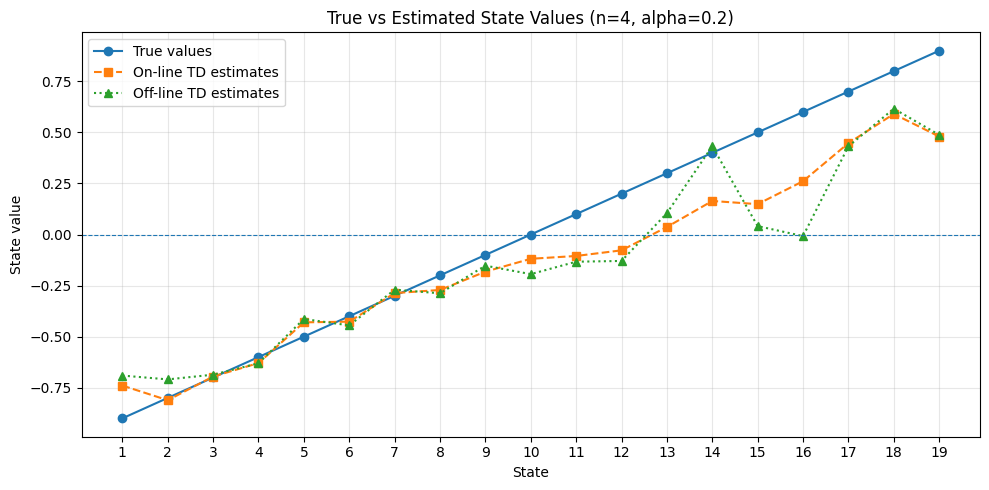

In [18]:
states_axis = np.arange(1, N_STATES + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    states_axis,
    TRUE_V,
    marker="o",
    linestyle="-",
    label="True values"
)

plt.plot(
    states_axis,
    V_online[1:20],
    marker="s",
    linestyle="--",
    label="On-line TD estimates"
)

plt.plot(
    states_axis,
    V_offline[1:20],
    marker="^",
    linestyle=":",
    label="Off-line TD estimates"
)

plt.axhline(0, linestyle="--", linewidth=0.8)

plt.xlabel("State")
plt.ylabel("State value")
plt.title(
    f"True vs Estimated State Values "
    f"(n={DEMO_N}, alpha={DEMO_ALPHA})"
)

plt.xticks(states_axis)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

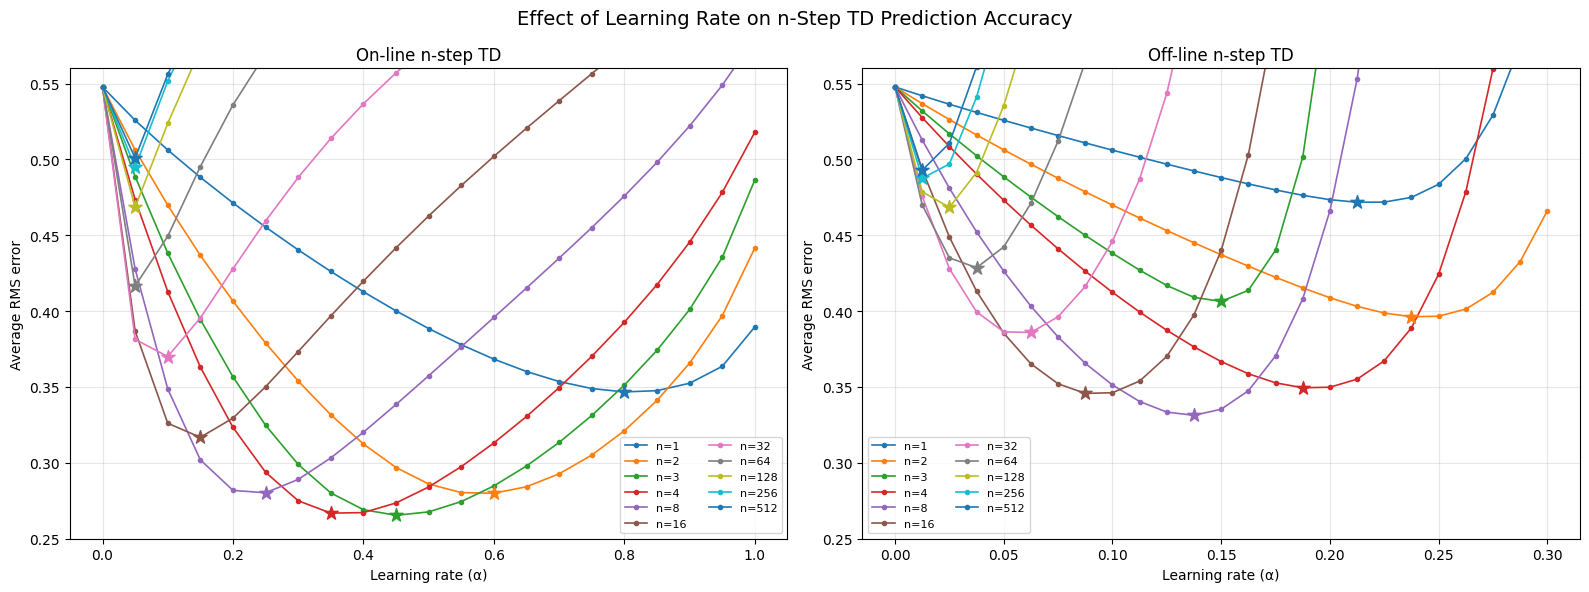

In [19]:
# Improved RMS error plots

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

configurations = [
    (axes[0], "online", alphas_on, "On-line n-step TD"),
    (axes[1], "offline", alphas_off, "Off-line n-step TD")
]

for ax, mode, alphas, title in configurations:

    for n in ns:

        rms_values = results[(mode, n)]

        # Plot the complete learning-rate curve
        ax.plot(
            alphas,
            rms_values,
            marker="o",
            markersize=3,
            linewidth=1.2,
            label=f"n={n}"
        )

        # Identify and highlight the best learning rate
        best_idx = int(np.argmin(rms_values))

        best_alpha = alphas[best_idx]
        best_rms = rms_values[best_idx]

        ax.scatter(
            best_alpha,
            best_rms,
            marker="*",
            s=100,
            zorder=5
        )

    ax.set_xlabel("Learning rate (α)")
    ax.set_ylabel("Average RMS error")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, ncol=2)

axes[0].set_ylim(0.25, 0.56)
axes[1].set_ylim(0.25, 0.56)

fig.suptitle(
    "Effect of Learning Rate on n-Step TD Prediction Accuracy",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [20]:
comparison_rows = []

for n in ns:

    online_values = results[("online", n)]
    offline_values = results[("offline", n)]

    online_idx = int(np.argmin(online_values))
    offline_idx = int(np.argmin(offline_values))

    online_best = online_values[online_idx]
    offline_best = offline_values[offline_idx]

    if online_best < offline_best:
        better_method = "On-line"
    elif offline_best < online_best:
        better_method = "Off-line"
    else:
        better_method = "Tie"

    comparison_rows.append({
        "n": n,
        "On-line Best α": alphas_on[online_idx],
        "On-line RMS": online_best,
        "Off-line Best α": alphas_off[offline_idx],
        "Off-line RMS": offline_best,
        "Lower RMS": better_method,
        "Absolute RMS Difference": abs(online_best - offline_best)
    })

comparison_df = pd.DataFrame(comparison_rows)

print("ON-LINE vs OFF-LINE COMPARISON")

display(
    comparison_df.style.format({
        "On-line Best α": "{:.4f}",
        "On-line RMS": "{:.4f}",
        "Off-line Best α": "{:.4f}",
        "Off-line RMS": "{:.4f}",
        "Absolute RMS Difference": "{:.4f}"
    })
)

ON-LINE vs OFF-LINE COMPARISON


,n,On-line Best α,On-line RMS,Off-line Best α,Off-line RMS,Lower RMS,Absolute RMS Difference
0,1,0.8000,0.3467,0.2125,0.4717,On-line,0.1250
1,2,0.6000,0.2800,0.2375,0.3963,On-line,0.1163
2,3,0.4500,0.2654,0.1500,0.4064,On-line,0.1409
3,4,0.3500,0.2669,0.1875,0.3495,On-line,0.0826
4,8,0.2500,0.2803,0.1375,0.3313,On-line,0.0510
5,16,0.1500,0.3168,0.0875,0.3458,On-line,0.0289
6,32,0.1000,0.3700,0.0625,0.3859,On-line,0.0159
7,64,0.0500,0.4165,0.0375,0.4286,On-line,0.0121
8,128,0.0500,0.4685,0.0250,0.4684,Off-line,0.0001
9,256,0.0500,0.4948,0.0125,0.4875,Off-line,0.0073


In [21]:
def run_method_episode_errors(runs, n, alpha, online):

    # One RMS error for every run and episode
    errs = np.zeros((len(runs), N_EPISODES))

    for r, eps in enumerate(runs):

        V = np.zeros(N_STATES + 2)

        for e, (states, R_T) in enumerate(eps):

            T = len(states) - 1

            if online:

                for t in range(T):

                    s = states[t]

                    G = n_step_return(
                        V, states, R_T, t, n, T
                    )

                    V[s] += alpha * (G - V[s])

            else:

                delta = np.zeros_like(V)

                for t in range(T):

                    s = states[t]

                    G = n_step_return(
                        V, states, R_T, t, n, T
                    )

                    delta[s] += alpha * (G - V[s])

                V += delta

            errs[r, e] = np.sqrt(
                np.mean(
                    (V[1:N_STATES + 1] - TRUE_V) ** 2
                )
            )

    # Average the errors across the independent runs
    return errs.mean(axis=0)

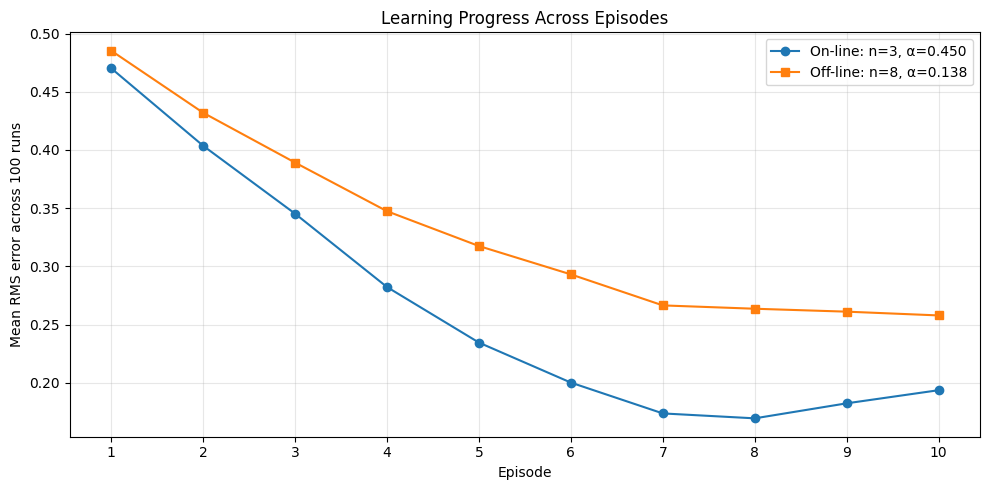

In [22]:
# Select the best configuration for each method

best_online_row = summary_df[
    summary_df["Method"] == "Online"
].loc[
    summary_df[summary_df["Method"] == "Online"]["Best RMS Error"].idxmin()
]

best_offline_row = summary_df[
    summary_df["Method"] == "Offline"
].loc[
    summary_df[summary_df["Method"] == "Offline"]["Best RMS Error"].idxmin()
]

n_on = int(best_online_row["n"])
alpha_on = float(best_online_row["Best Learning Rate (α)"])

n_off = int(best_offline_row["n"])
alpha_off = float(best_offline_row["Best Learning Rate (α)"])

online_episode_errors = run_method_episode_errors(
    runs, n_on, alpha_on, True
)

offline_episode_errors = run_method_episode_errors(
    runs, n_off, alpha_off, False
)

episodes = np.arange(1, N_EPISODES + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    episodes,
    online_episode_errors,
    marker="o",
    label=f"On-line: n={n_on}, α={alpha_on:.3f}"
)

plt.plot(
    episodes,
    offline_episode_errors,
    marker="s",
    label=f"Off-line: n={n_off}, α={alpha_off:.3f}"
)

plt.xlabel("Episode")
plt.ylabel("Mean RMS error across 100 runs")
plt.title("Learning Progress Across Episodes")
plt.xticks(episodes)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()